# BÁO CÁO HUẤN LUYỆN VÀ SO SÁNH CÁC MÔ HÌNH PHÂN LOẠI CHỮ SỐ MNIST

Notebook thực hiện huấn luyện lại các mô hình tự cài đặt, đối chiếu với các mô hình Scikit-learn và bổ sung mô hình CNN sử dụng PyTorch. Các mô hình được đánh giá trên tập MNIST Test bằng Accuracy, Macro Precision, Macro Recall và Macro F1; đồng thời ghi nhận thời gian huấn luyện và dự đoán khi có thể đo được.

Các mô hình được đưa vào báo cáo:
- **Custom:** Logistic Regression, Gaussian Naive Bayes, MLP và Soft Voting (MLP + Random Forest + KNN).
- **Scikit-learn:** Logistic Regression, GaussianNB, MLPClassifier, Random Forest và KNN.
- **Deep Learning:** CNN với hai tầng đặc trưng có số kênh cấu hình `c1=32`, `c2=64`.

CNN xử lý ảnh đầu vào dạng 28×28, trong khi các mô hình còn lại xử lý vector đặc trưng 784 chiều. Vì vậy, CNN được huấn luyện bằng pipeline ảnh riêng. Kết quả CNN được đưa vào bảng tổng hợp để tham khảo, nhưng cần lưu ý sự khác biệt về cách chia Train/Validation và tiền xử lý khi diễn giải mức độ công bằng của phép so sánh.

Notebook CNN riêng còn có một thí nghiệm tăng cường dữ liệu bằng phép xoay ảnh. Thí nghiệm này được trình bày như phần khảo sát bổ sung, không gộp vào hàng CNN cơ bản trong bảng so sánh chính.

## 1. Chuẩn bị dữ liệu

Dùng một lần chia Train/Validation/Test chung: Validation dùng cho early stopping/chọn cấu hình; Test chỉ dùng đánh giá cuối. Không đưa kết quả cũ vào bảng benchmark mới.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "requirements.txt").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Không tìm thấy project root có requirements.txt, src/ và data/.")
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"
train_data = np.load(DATA_DIR / "mnist_train.npz")
test_data = np.load(DATA_DIR / "mnist_test.npz")
X_train_raw, y_train_raw = train_data["X"], train_data["y"].astype(int)
X_test_raw, y_test = test_data["X"], test_data["y"].astype(int)

from src.preprocessing.scaler import split_val, scale_flat
from src.models.logistic_regression import LogisticRegression
from src.models.naive_bayes import GaussianNaiveBayes
from src.models.mlp import MLP
from src.evaluation.metrics import ClassificationMetrics

X_train, X_val, y_train, y_val = split_val(
    X=X_train_raw, y=y_train_raw, val_size=0.1, seed=SEED
)
X_train, X_val, X_test, scaler_tools = scale_flat(
    X_train=X_train, X_test=X_test_raw, X_val=X_val, mode="standard"
)
X_train = np.asarray(X_train).reshape(len(X_train), -1)
X_val = np.asarray(X_val).reshape(len(X_val), -1)
X_test = np.asarray(X_test).reshape(len(X_test), -1)
y_train, y_val = np.asarray(y_train, int), np.asarray(y_val, int)
LABELS = np.arange(10)
print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

Global Mean: 0.1307, Global Std: 0.3082
Train: (54000, 784) Validation: (6000, 784) Test: (10000, 784)


## 2. Train lại các best model tự cài đặt

Các model được khởi tạo mới. Đo thời gian fit và predict trong lần chạy này.

In [2]:
import torch
torch.set_grad_enabled(False)
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

def to_numpy(value):
    if hasattr(value, "detach"):
        return value.detach().cpu().numpy()
    return np.asarray(value)

def metric_row(name, y_true, y_pred, train_seconds, predict_seconds):
    pred = to_numpy(y_pred).reshape(-1).astype(int)
    m = ClassificationMetrics(y_true=np.asarray(y_true), y_pred=pred, labels=LABELS).evaluate()
    return {
        "Model": name, "Accuracy": m["accuracy"],
        "Macro Precision": m["macro_precision"],
        "Macro Recall": m["macro_recall"], "Macro F1": m["macro_f1"],
        "Train time (s)": train_seconds, "Predict time (s)": predict_seconds
    }

custom_rows, custom_predictions, custom_models = [], {}, {}
def save_custom_result(name, model, train_s):
    t0 = time.perf_counter()
    pred = to_numpy(model.predict(X_test)).reshape(-1).astype(int)
    pred_s = time.perf_counter() - t0
    custom_rows.append(metric_row(name, y_test, pred, train_s, pred_s))
    custom_predictions[name], custom_models[name] = pred, model

# Custom Logistic Regression
lr = LogisticRegression(eta=0.03, lam=0.001, max_epochs=26,
                         batch_size=128, patience=6, seed=SEED)
t0 = time.perf_counter()
lr.fit(X_train, y_train, X_val=X_val, y_val=y_val)
lr_train_s = time.perf_counter() - t0
save_custom_result("Custom Logistic Regression", lr, lr_train_s)

# Custom Gaussian Naive Bayes
gnb = GaussianNaiveBayes(0.1, batch_size=512)
t0 = time.perf_counter()
gnb.fit(X_train, y_train)
gnb_train_s = time.perf_counter() - t0
save_custom_result("Custom GaussianNB", gnb, gnb_train_s)

# Custom MLP
MLP_CONFIG = dict(sizes=[784, 500, 10], lr=0.05, momentum=0.9,
                  p_drop=0.0, weight_decay=0.0001,
                  batch_size=128, max_epochs=37, patience=6)
mlp = MLP(sizes=MLP_CONFIG["sizes"], activation="relu", p_drop=0.0,
          init="he", seed=SEED)
t0 = time.perf_counter()
mlp.fit(X_train, y_train, validation_data=(X_val, y_val),
        epochs=MLP_CONFIG["max_epochs"], batch_size=MLP_CONFIG["batch_size"],
        lr=MLP_CONFIG["lr"], patience=MLP_CONFIG["patience"],
        weight_decay=MLP_CONFIG["weight_decay"],
        momentum=MLP_CONFIG["momentum"], seed=SEED, verbose=True)
mlp_train_s = time.perf_counter() - t0
save_custom_result("Custom MLP", mlp, mlp_train_s)

print(pd.DataFrame(custom_rows).to_string(index=False))

Epoch 01/37 | train loss 0.0939 acc 0.9697 | val loss 0.1340 acc 0.9590
Epoch 02/37 | train loss 0.0446 acc 0.9865 | val loss 0.1000 acc 0.9718
Epoch 03/37 | train loss 0.0266 acc 0.9919 | val loss 0.0922 acc 0.9733
Epoch 04/37 | train loss 0.0157 acc 0.9962 | val loss 0.0845 acc 0.9748
Epoch 05/37 | train loss 0.0110 acc 0.9972 | val loss 0.0813 acc 0.9807
Epoch 06/37 | train loss 0.0081 acc 0.9983 | val loss 0.0824 acc 0.9797
Epoch 07/37 | train loss 0.0058 acc 0.9993 | val loss 0.0758 acc 0.9812
Epoch 08/37 | train loss 0.0034 acc 0.9998 | val loss 0.0745 acc 0.9810
Epoch 09/37 | train loss 0.0022 acc 1.0000 | val loss 0.0753 acc 0.9827
Epoch 10/37 | train loss 0.0018 acc 1.0000 | val loss 0.0733 acc 0.9832
Epoch 11/37 | train loss 0.0022 acc 0.9999 | val loss 0.0755 acc 0.9828
Epoch 12/37 | train loss 0.0018 acc 1.0000 | val loss 0.0720 acc 0.9837
Epoch 13/37 | train loss 0.0017 acc 1.0000 | val loss 0.0735 acc 0.9832
Epoch 14/37 | train loss 0.0017 acc 1.0000 | val loss 0.0733 acc

### 2.1. Custom Soft Voting

Ensemble theo notebook gốc: MLP + Random Forest + KNN, trọng số `[2,1,1]`. MLP dùng best config; RF dùng 200 cây, `min_samples_split=5`; KNN dùng `k=3`, distance weighting.

In [3]:
class CustomSoftVoting:
    def __init__(self):
        self.mlp = MLP(sizes=MLP_CONFIG["sizes"], activation="relu",
                       p_drop=0.0, init="he", seed=SEED)
        self.rf = RandomForestClassifier(n_estimators=200, max_depth=None,
                                         min_samples_split=5, random_state=SEED,
                                         n_jobs=-1)
        self.knn = KNeighborsClassifier(n_neighbors=3, weights="distance",
                                        metric="euclidean", n_jobs=-1)
        self.weights = np.array([2.0, 1.0, 1.0])

    def fit(self, X, y, X_val, y_val):
        self.mlp.fit(X, y, validation_data=(X_val, y_val),
                     epochs=MLP_CONFIG["max_epochs"],
                     batch_size=MLP_CONFIG["batch_size"],
                     lr=MLP_CONFIG["lr"], patience=MLP_CONFIG["patience"],
                     weight_decay=MLP_CONFIG["weight_decay"],
                     momentum=MLP_CONFIG["momentum"], seed=SEED, verbose=True)
        self.rf.fit(X, y)
        self.knn.fit(X, y)
        return self

    def predict(self, X):
        p_mlp = to_numpy(self.mlp.predict_proba(X))
        p_rf, p_knn = self.rf.predict_proba(X), self.knn.predict_proba(X)
        w = self.weights / self.weights.sum()
        return np.argmax(w[0]*p_mlp + w[1]*p_rf + w[2]*p_knn, axis=1)

ensemble = CustomSoftVoting()
t0 = time.perf_counter()
ensemble.fit(X_train, y_train, X_val, y_val)
ensemble_train_s = time.perf_counter() - t0
save_custom_result("Custom Soft Voting (MLP + RF + KNN)", ensemble, ensemble_train_s)
custom_results = pd.DataFrame(custom_rows)
display(custom_results.sort_values("Accuracy", ascending=False).reset_index(drop=True))

Epoch 01/37 | train loss 0.0939 acc 0.9697 | val loss 0.1340 acc 0.9590
Epoch 02/37 | train loss 0.0446 acc 0.9865 | val loss 0.1000 acc 0.9718
Epoch 03/37 | train loss 0.0266 acc 0.9919 | val loss 0.0922 acc 0.9733
Epoch 04/37 | train loss 0.0157 acc 0.9962 | val loss 0.0845 acc 0.9748
Epoch 05/37 | train loss 0.0110 acc 0.9972 | val loss 0.0813 acc 0.9807
Epoch 06/37 | train loss 0.0081 acc 0.9983 | val loss 0.0824 acc 0.9797
Epoch 07/37 | train loss 0.0058 acc 0.9993 | val loss 0.0758 acc 0.9812
Epoch 08/37 | train loss 0.0034 acc 0.9998 | val loss 0.0745 acc 0.9810
Epoch 09/37 | train loss 0.0022 acc 1.0000 | val loss 0.0753 acc 0.9827
Epoch 10/37 | train loss 0.0018 acc 1.0000 | val loss 0.0733 acc 0.9832
Epoch 11/37 | train loss 0.0022 acc 0.9999 | val loss 0.0755 acc 0.9828
Epoch 12/37 | train loss 0.0018 acc 1.0000 | val loss 0.0720 acc 0.9837
Epoch 13/37 | train loss 0.0017 acc 1.0000 | val loss 0.0735 acc 0.9832
Epoch 14/37 | train loss 0.0017 acc 1.0000 | val loss 0.0733 acc

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Train time (s),Predict time (s)
0,Custom Soft Voting (MLP + RF + KNN),0.9848,0.984733,0.984713,0.984712,59.770559,6.000782
1,Custom MLP,0.9835,0.983397,0.983377,0.983381,48.742384,0.029717
2,Custom Logistic Regression,0.9254,0.924355,0.924316,0.924276,5.766049,0.024508
3,Custom GaussianNB,0.8149,0.831217,0.811157,0.813252,0.498062,0.421707


## 3. Chọn và đánh giá best model Scikit-learn

Các ứng viên được fit trên cùng Train, chọn theo Macro F1 Validation. Sau đó dự đoán Test. `C` của sklearn LogisticRegression là nghịch đảo mức regularization, không đồng nhất trực tiếp với `lam` custom. MLPClassifier cũng khác optimizer/khởi tạo/early stopping so với MLP tự cài đặt.

In [4]:
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.naive_bayes import GaussianNB as SkGaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

candidates = {
    "Sklearn Logistic Regression": [
        SkLogisticRegression(C=c, solver="lbfgs", max_iter=400, random_state=SEED)
        for c in [10.0, 100.0, 1000.0]
    ],
    "Sklearn GaussianNB": [
        SkGaussianNB(var_smoothing=v) for v in [1e-3, 1e-2, 1e-1, 2e-1]
    ],
    "Sklearn MLPClassifier": [
        MLPClassifier(hidden_layer_sizes=h, activation="relu", solver="adam",
                      alpha=1e-4, batch_size=128, learning_rate_init=0.001,
                      max_iter=100, early_stopping=True, validation_fraction=0.1,
                      n_iter_no_change=8, random_state=SEED)
        for h in [(128,), (256,), (500,), (256, 128)]
    ],
    "Sklearn Random Forest": [
        RandomForestClassifier(n_estimators=200, max_depth=None,
                               min_samples_split=5, random_state=SEED, n_jobs=-1)
    ],
    "Sklearn KNN": [
        KNeighborsClassifier(n_neighbors=k, weights="distance", n_jobs=-1)
        for k in [3, 5, 7]
    ],
}

best_sklearn, val_rows = {}, []
for family, models in candidates.items():
    best_score, best_model, best_fit_seconds = -1, None, np.nan
    for candidate in models:
        t0 = time.perf_counter()
        candidate.fit(X_train, y_train)
        fit_s = time.perf_counter() - t0
        val_pred = candidate.predict(X_val)
        val_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
        val_acc = accuracy_score(y_val, val_pred)
        val_rows.append({"Model family": family, "Validation Accuracy": val_acc,
                         "Validation Macro F1": val_f1, "Fit time (s)": fit_s})
        if val_f1 > best_score:
            best_score, best_model = val_f1, candidate
            best_fit_seconds = fit_s
    best_sklearn[family] = {
        "model": best_model,
        "validation_macro_f1": best_score,
        "train_seconds": best_fit_seconds,
    }

validation_results = pd.DataFrame(val_rows).sort_values(
    "Validation Macro F1", ascending=False
).reset_index(drop=True)
display(validation_results)


/home/nguyenhaianh/Desktop/Classify_Number/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 400 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=400).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/nguyenhaianh/Desktop/Classify_Number/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 400 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=400).
You might also want to scale the data as shown in:
    htt

,Model family,Validation Accuracy,Validation Macro F1,Fit time (s)
0,Sklearn MLPClassifier,0.982167,0.982073,59.001403
1,Sklearn MLPClassifier,0.981667,0.981514,103.189088
2,Sklearn MLPClassifier,0.978667,0.978593,40.408987
3,Sklearn MLPClassifier,0.972833,0.972678,11.719475
4,Sklearn KNN,0.972333,0.972299,0.012813
5,Sklearn KNN,0.969500,0.969481,0.012772
6,Sklearn KNN,0.967333,0.967353,0.014298
7,Sklearn Random Forest,0.967000,0.966825,9.389872
8,Sklearn Logistic Regression,0.917333,0.916472,67.334839
9,Sklearn Logistic Regression,0.917167,0.916263,67.349378


In [5]:
sklearn_rows, sklearn_predictions, sklearn_models = [], {}, {}
for family, item in best_sklearn.items():
    model = item["model"]
    t0 = time.perf_counter()
    pred = model.predict(X_test)
    pred_s = time.perf_counter() - t0
    sklearn_predictions[family], sklearn_models[family] = pred, model

    m = ClassificationMetrics(y_true=y_test, y_pred=pred, labels=LABELS).evaluate()
    fit_s = item["train_seconds"]
    sklearn_rows.append({
        "Model": family, "Accuracy": m["accuracy"],
        "Macro Precision": m["macro_precision"], "Macro Recall": m["macro_recall"],
        "Macro F1": m["macro_f1"], "Train time (s)": fit_s,
        "Predict time (s)": pred_s
    })

sklearn_results = pd.DataFrame(sklearn_rows)
display(sklearn_results.sort_values("Accuracy", ascending=False).reset_index(drop=True))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Train time (s),Predict time (s)
0,Sklearn MLPClassifier,0.9817,0.981735,0.981516,0.981610,59.001403,0.022806
1,Sklearn KNN,0.9709,0.971090,0.970555,0.970726,0.012813,5.318095
2,Sklearn Random Forest,0.9690,0.968801,0.968689,0.968723,9.389872,0.256824
3,Sklearn Logistic Regression,0.9202,0.919373,0.919091,0.919125,67.334839,0.012876
4,Sklearn GaussianNB,0.8149,0.831217,0.811157,0.813252,0.194464,0.203057


## 3. Huấn luyện và đánh giá CNN (PyTorch)

CNN nhận trực tiếp ảnh MNIST kích thước 28×28 thay vì vector hóa thành 784 phần tử. Ảnh được chuyển sang Tensor và chuẩn hóa về khoảng [0, 1] bằng `ToTensor()`.

Cấu hình lấy từ notebook huấn luyện CNN:
- `c1=32`, `c2=64`; tổng số tham số ghi nhận là 421.642.
- Batch size = 128; learning rate = 0,001.
- Số epoch tối đa = 30; Early Stopping với patience = 6.
- Chia 60.000 ảnh train ban đầu thành 50.000 ảnh Train và 10.000 ảnh Validation.
- Tập Test gồm 10.000 ảnh MNIST chuẩn.

Lưu ý: pipeline CNN sử dụng cách chia 50.000/10.000 và chuẩn hóa [0,1], khác với pipeline vector hóa và StandardScaler của các mô hình phía trên. Do đó, bảng so sánh phản ánh kết quả thực nghiệm của từng pipeline, không phải benchmark kiểm soát hoàn toàn mọi điều kiện.

CNN device: cpu


100.0%
100.0%
100.0%
100.0%


CNN parameters: 421,642
Epoch 1/30 | Train loss: 0.0750, acc: 0.9784 | Val loss: 0.0879, acc: 0.9739
Epoch 2/30 | Train loss: 0.0426, acc: 0.9872 | Val loss: 0.0601, acc: 0.9826
Epoch 3/30 | Train loss: 0.0375, acc: 0.9887 | Val loss: 0.0592, acc: 0.9819
Epoch 4/30 | Train loss: 0.0243, acc: 0.9927 | Val loss: 0.0467, acc: 0.9861
Epoch 5/30 | Train loss: 0.0214, acc: 0.9930 | Val loss: 0.0492, acc: 0.9856
Epoch 6/30 | Train loss: 0.0150, acc: 0.9951 | Val loss: 0.0437, acc: 0.9868
Epoch 7/30 | Train loss: 0.0107, acc: 0.9966 | Val loss: 0.0416, acc: 0.9876
Epoch 8/30 | Train loss: 0.0145, acc: 0.9951 | Val loss: 0.0461, acc: 0.9870
Epoch 9/30 | Train loss: 0.0111, acc: 0.9964 | Val loss: 0.0476, acc: 0.9873
Epoch 10/30 | Train loss: 0.0081, acc: 0.9974 | Val loss: 0.0496, acc: 0.9869
Epoch 11/30 | Train loss: 0.0070, acc: 0.9978 | Val loss: 0.0487, acc: 0.9872
Epoch 12/30 | Train loss: 0.0110, acc: 0.9962 | Val loss: 0.0517, acc: 0.9874
Epoch 13/30 | Train loss: 0.0053, acc: 0.9983 | V

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Train time (s),Predict time (s)
0,CNN (PyTorch),0.9913,0.991324,0.991164,0.991235,317.885671,1.572186


     Class  Precision     Recall         F1
         0      0.991      0.996      0.993 
         1      0.993      0.998      0.996 
         2      0.993      0.985      0.989 
         3      0.988      0.999      0.994 
         4      0.990      0.994      0.992 
         5      0.994      0.985      0.990 
         6      0.993      0.991      0.992 
         7      0.989      0.990      0.990 
         8      0.992      0.988      0.990 
         9      0.990      0.985      0.988 
 Macro avg      0.991      0.991      0.991 

Accuracy: 0.991


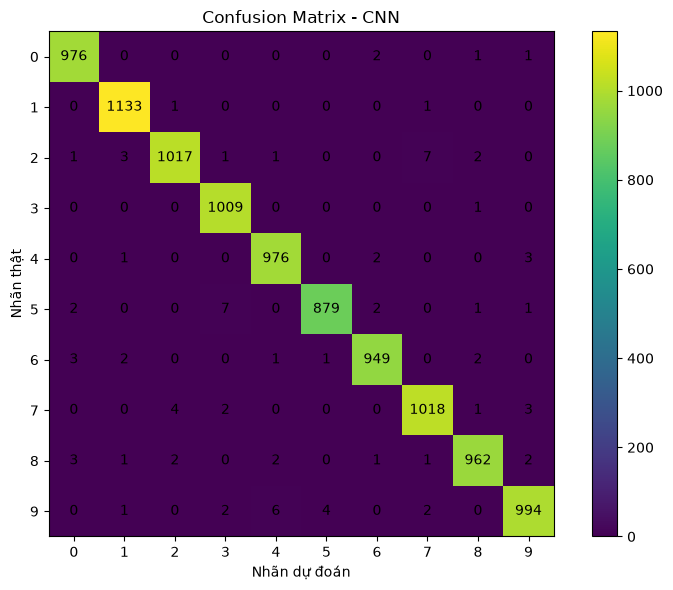

In [6]:
# Cho phép autograd vì phần huấn luyện CNN cần tính gradient.
import torch
torch.set_grad_enabled(True)

from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from src.models.cnn import CNN, Trainer

BATCH_SIZE_CNN = 128
CNN_EPOCHS = 30
CNN_LR = 0.001
CNN_PATIENCE = 6
CNN_C1, CNN_C2 = 32, 64
CNN_SEED = 42

torch.manual_seed(CNN_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("CNN device:", device)

cnn_transform = transforms.ToTensor()
cnn_full_train = datasets.MNIST(
    root=str(PROJECT_ROOT / "data"),
    train=True,
    download=True,
    transform=cnn_transform,
)
cnn_test_data = datasets.MNIST(
    root=str(PROJECT_ROOT / "data"),
    train=False,
    download=True,
    transform=cnn_transform,
)

cnn_train_data, cnn_val_data = random_split(
    cnn_full_train,
    [50000, 10000],
    generator=torch.Generator().manual_seed(CNN_SEED),
)

cnn_train_loader = DataLoader(
    cnn_train_data, batch_size=BATCH_SIZE_CNN, shuffle=True
)
cnn_val_loader = DataLoader(
    cnn_val_data, batch_size=BATCH_SIZE_CNN, shuffle=False
)
cnn_test_loader = DataLoader(
    cnn_test_data, batch_size=BATCH_SIZE_CNN, shuffle=False
)

cnn_model = CNN(c1=CNN_C1, c2=CNN_C2)
cnn_trainer = Trainer(cnn_model, device, lr=CNN_LR)
cnn_num_params = sum(p.numel() for p in cnn_model.parameters())
print(f"CNN parameters: {cnn_num_params:,}")

t0 = time.perf_counter()
cnn_history = cnn_trainer.fit(
    cnn_train_loader,
    cnn_val_loader,
    epochs=CNN_EPOCHS,
    patience=CNN_PATIENCE,
)
cnn_train_seconds = time.perf_counter() - t0

cnn_test_result = cnn_trainer.evaluate(cnn_test_loader, collect=True)
cnn_y_true = cnn_test_result["labels"].detach().cpu().numpy()
cnn_y_pred = cnn_test_result["probs"].argmax(dim=1).detach().cpu().numpy()

cnn_metric = ClassificationMetrics(
    y_true=cnn_y_true,
    y_pred=cnn_y_pred,
    labels=LABELS,
).evaluate()

# Đo thời gian dự đoán trên toàn bộ tập Test.
cnn_model.eval()
t0 = time.perf_counter()
with torch.no_grad():
    for cnn_images, _ in cnn_test_loader:
        cnn_model(cnn_images.to(device))
cnn_predict_seconds = time.perf_counter() - t0

cnn_results = pd.DataFrame([{
    "Model": "CNN (PyTorch)",
    "Accuracy": cnn_metric["accuracy"],
    "Macro Precision": cnn_metric["macro_precision"],
    "Macro Recall": cnn_metric["macro_recall"],
    "Macro F1": cnn_metric["macro_f1"],
    "Train time (s)": cnn_train_seconds,
    "Predict time (s)": cnn_predict_seconds,
}])

print("CNN Test loss:", round(float(cnn_test_result["loss"]), 4))
display(cnn_results)

# Báo cáo theo từng chữ số và confusion matrix.
cnn_metrics_report = ClassificationMetrics(
    y_true=cnn_y_true,
    y_pred=cnn_y_pred,
    labels=LABELS,
)
cnn_metrics_report.report()

cm, cm_labels = cnn_metrics_report.get_confustion_matrix()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cm, interpolation="nearest")
ax.set_title("Confusion Matrix - CNN")
ax.set_xlabel("Nhãn dự đoán")
ax.set_ylabel("Nhãn thật")
ax.set_xticks(np.arange(len(cm_labels)), labels=cm_labels)
ax.set_yticks(np.arange(len(cm_labels)), labels=cm_labels)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


## 4. So sánh tổng hợp và theo từng họ thuật toán

In [7]:
custom_results["Implementation"] = "Custom"
sklearn_results["Implementation"] = "Scikit-learn"
cnn_results["Implementation"] = "CNN / PyTorch"
all_comparison = pd.concat([custom_results, sklearn_results, cnn_results], ignore_index=True)
all_comparison = all_comparison.sort_values(
    ["Accuracy", "Macro F1"], ascending=False
).reset_index(drop=True)
display(all_comparison)

pairs = [
    ("Logistic Regression", "Custom Logistic Regression", "Sklearn Logistic Regression"),
    ("Gaussian Naive Bayes", "Custom GaussianNB", "Sklearn GaussianNB"),
    ("MLP", "Custom MLP", "Sklearn MLPClassifier"),
]
pair_rows = []
for family, custom_name, sklearn_name in pairs:
    a = custom_results.loc[custom_results.Model == custom_name].iloc[0]
    b = sklearn_results.loc[sklearn_results.Model == sklearn_name].iloc[0]
    pair_rows.append({
        "Algorithm": family,
        "Custom Accuracy": a["Accuracy"], "Sklearn Accuracy": b["Accuracy"],
        "Accuracy diff (Sklearn - Custom)": b["Accuracy"] - a["Accuracy"],
        "Custom Macro F1": a["Macro F1"], "Sklearn Macro F1": b["Macro F1"],
        "Macro F1 diff (Sklearn - Custom)": b["Macro F1"] - a["Macro F1"],
    })
paired_comparison = pd.DataFrame(pair_rows)
display(paired_comparison)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Train time (s),Predict time (s),Implementation
0,CNN (PyTorch),0.9913,0.991324,0.991164,0.991235,317.885671,1.572186,CNN / PyTorch
1,Custom Soft Voting (MLP + RF + KNN),0.9848,0.984733,0.984713,0.984712,59.770559,6.000782,Custom
2,Custom MLP,0.9835,0.983397,0.983377,0.983381,48.742384,0.029717,Custom
3,Sklearn MLPClassifier,0.9817,0.981735,0.981516,0.981610,59.001403,0.022806,Scikit-learn
4,Sklearn KNN,0.9709,0.971090,0.970555,0.970726,0.012813,5.318095,Scikit-learn
5,Sklearn Random Forest,0.9690,0.968801,0.968689,0.968723,9.389872,0.256824,Scikit-learn
6,Custom Logistic Regression,0.9254,0.924355,0.924316,0.924276,5.766049,0.024508,Custom
7,Sklearn Logistic Regression,0.9202,0.919373,0.919091,0.919125,67.334839,0.012876,Scikit-learn
8,Custom GaussianNB,0.8149,0.831217,0.811157,0.813252,0.498062,0.421707,Custom
9,Sklearn GaussianNB,0.8149,0.831217,0.811157,0.813252,0.194464,0.203057,Scikit-learn


,Algorithm,Custom Accuracy,Sklearn Accuracy,Accuracy diff (Sklearn - Custom),Custom Macro F1,Sklearn Macro F1,Macro F1 diff (Sklearn - Custom)
0,Logistic Regression,0.9254,0.9202,-0.0052,0.924276,0.919125,-0.005152
1,Gaussian Naive Bayes,0.8149,0.8149,0.0000,0.813252,0.813252,0.000000
2,MLP,0.9835,0.9817,-0.0018,0.983381,0.981610,-0.001771


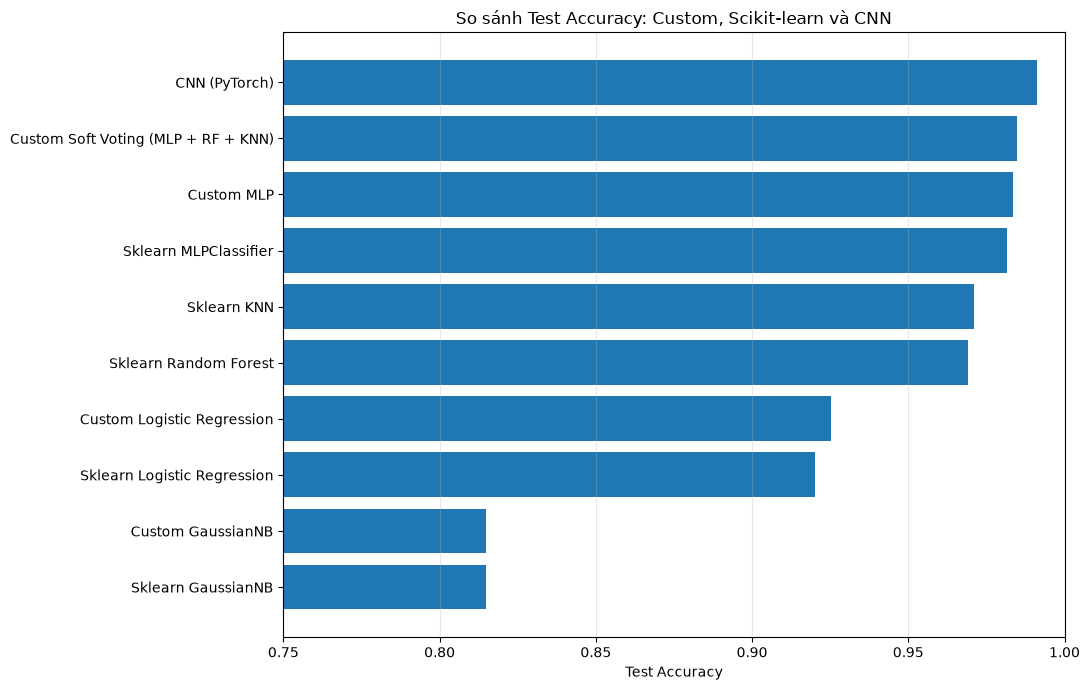

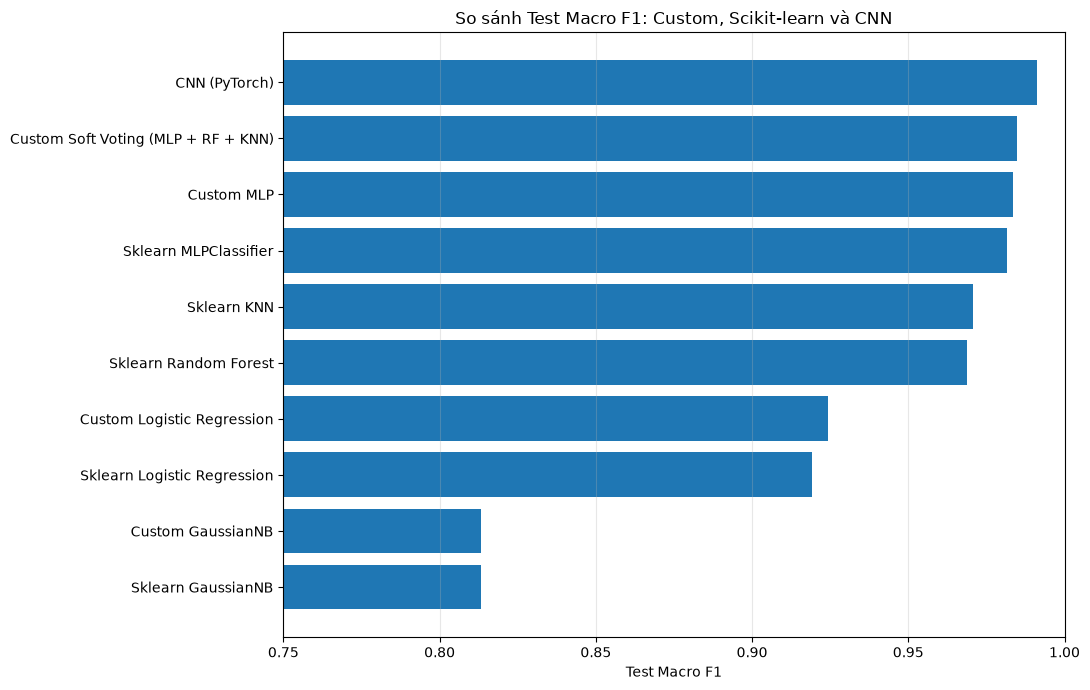

In [8]:
fig, ax = plt.subplots(figsize=(11, 7))
plot_df = all_comparison.sort_values("Accuracy")
ax.barh(plot_df["Model"], plot_df["Accuracy"])
ax.set_xlim(0.75, 1.0)
ax.set_xlabel("Test Accuracy")
ax.set_title("So sánh Test Accuracy: Custom, Scikit-learn và CNN")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 7))
plot_df = all_comparison.sort_values("Macro F1")
ax.barh(plot_df["Model"], plot_df["Macro F1"])
ax.set_xlim(0.75, 1.0)
ax.set_xlabel("Test Macro F1")
ax.set_title("So sánh Test Macro F1: Custom, Scikit-learn và CNN")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Nhận xét và kết luận

Dựa vào bảng `all_comparison` sau khi chạy toàn bộ notebook:

- Xác định mô hình có Accuracy cao nhất; đối chiếu thêm Macro F1 để đánh giá mức cân bằng giữa 10 lớp chữ số.
- Với Logistic Regression, Gaussian Naive Bayes và MLP, dùng `paired_comparison` để so sánh phiên bản tự cài đặt với Scikit-learn.
- CNN khai thác cấu trúc không gian của ảnh thông qua các tầng tích chập, nên phù hợp tự nhiên với dữ liệu ảnh hơn các mô hình nhận vector 784 chiều.
- Soft Voting chỉ được xem là có lợi nếu cải thiện Accuracy/Macro F1 so với các mô hình thành phần; cần cân nhắc thêm thời gian dự đoán.
- Không kết luận một thư viện hoặc kiến trúc luôn tốt hơn chỉ từ một lần chạy. Thời gian phụ thuộc thiết bị, phiên bản thư viện và tải hệ thống.

**Lưu ý khi diễn giải kết quả:** các mô hình Custom/Scikit-learn dùng tập Train/Validation được tạo từ `split_val` và dữ liệu được chuẩn hóa bằng `StandardScaler`. CNN dùng 50.000 ảnh Train, 10.000 ảnh Validation và `ToTensor()` đưa pixel về [0,1]. Cả hai pipeline đánh giá trên tập MNIST Test chuẩn, nhưng cách chia Train/Validation và tiền xử lý khác nhau. Vì vậy, kết quả có giá trị tham khảo; để benchmark nghiêm ngặt cần thống nhất chỉ số mẫu Train/Validation, tiền xử lý và seed.

Thời gian train CNN được đo riêng trong pipeline PyTorch; thời gian dự đoán được đo trên toàn bộ tập Test theo batch. So sánh thời gian chỉ mang tính tham khảo vì khác biệt framework, thiết bị và cách triển khai.

### 5.1. Thí nghiệm tăng cường dữ liệu bằng phép xoay

Notebook `train_cnn_rotation` còn huấn luyện một CNN thứ hai với `RandomRotation(30°)` trên ảnh Train. Kết quả cho thấy đây là một thí nghiệm riêng nhằm khảo sát khả năng tổng quát hóa với ảnh bị xoay. Khi báo cáo kết quả thí nghiệm này, nên đánh giá cả ảnh gốc (0°) và ảnh kiểm thử được xoay ở các góc -45°, -30°, -15°, 15°, 30°, 45°. Không gộp kết quả CNN tăng cường dữ liệu với CNN cơ bản nếu chưa xác định rõ mục tiêu so sánh.